# Module 1 — PyTorch en pratique

> **Objectif** : maîtriser les outils PyTorch qu'on utilisera dans tout le cours : tenseurs et leurs formes, autograd, `nn.Module`, `Dataset`/`DataLoader` avec *padding* pour des séquences de longueurs variables, et une boucle d'entraînement robuste et déboguable. On termine par un mini-projet « NLP-like » de bout en bout.

| | |
|---|---|
| **Durée estimée** | 2 à 3 h |
| **Prérequis** | Module 0 |
| **Librairies** | `torch` (≥ 2.0), `numpy`, `matplotlib` |

**Plan**

1. Pourquoi PyTorch
2. Les tenseurs : formes, vues, broadcasting, `einsum`
3. Autograd en profondeur
4. `nn.Module` : construire ses propres couches
5. Les données : `Dataset`, `DataLoader`, padding et masques
6. Une boucle d'entraînement robuste
7. Déboguer un réseau de neurones
8. Mini-projet : classifier des séquences de longueur variable
9. Récapitulatif et exercices

> ⚙️ **Installation** : `pip install torch` (CPU) ou suivre pytorch.org pour CUDA. Sur Google Colab, PyTorch est préinstallé (Exécution → Modifier le type d'exécution → GPU). Les cellules NumPy de ce notebook illustrent les concepts et tournent partout.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
rng = np.random.default_rng(0)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(f"torch {torch.__version__} | device = {device}")

## 1. Pourquoi PyTorch ?

PyTorch fournit trois choses, que tu as codées à la main au module 0 :

| Ce que tu as codé | Ce que fournit PyTorch |
|---|---|
| tableaux NumPy | `torch.Tensor`, sur CPU **ou GPU**, avec des noyaux optimisés |
| la classe `Value` et ses `_backward` | **autograd** : graphe dynamique construit à la volée, `loss.backward()` |
| `MLP`, `softmax`, `Adam`… | `torch.nn` (couches, pertes), `torch.optim` (optimiseurs), `torch.utils.data` |

Le graphe est **dynamique** (*define-by-run*) : il est reconstruit à chaque passe avant, en suivant le code Python réellement exécuté. On peut donc utiliser des `if`, des boucles de longueur variable, `print` et le débogueur n'importe où. C'est précieux en NLP, où les séquences ont des longueurs variables.

## 2. Les tenseurs

### 2.1 Création, `dtype`, `device`

In [ ]:
a = torch.tensor([[1, 2, 3], [4, 5, 6]])            # from Python data -> int64
b = torch.zeros(2, 3)                                 # float32 by default
c = torch.randn(2, 3, dtype=torch.float64)           # standard normal
d = torch.arange(6).reshape(2, 3)
e = torch.from_numpy(np.ones((2, 3)))                # shares memory with the numpy array!
print(a.dtype, b.dtype, c.dtype, e.dtype)
print("shape:", a.shape, "| ndim:", a.ndim, "| numel:", a.numel())

x = torch.randn(3, 4).to(device)                     # move to GPU if available
print(x.device)
# Operations require all tensors on the same device: x + torch.ones(3, 4) would fail on GPU.

**Les `dtype` à connaître en NLP :**

| `dtype` | Usage |
|---|---|
| `torch.long` (int64) | **indices de tokens**, étiquettes de classes (exigé par `nn.Embedding` et `F.cross_entropy`) |
| `torch.float32` | poids et activations par défaut |
| `torch.bfloat16` / `float16` | entraînement en précision mixte (GPU récents) |
| `torch.bool` | masques (padding, attention causale) |

### 2.2 Les conventions de forme en NLP

Retiens cette convention, utilisée partout dans le cours :

$$
\underbrace{B}_{\text{batch}} \times \underbrace{T}_{\text{longueur de séquence (tokens)}} \times \underbrace{C}_{\text{dimension des vecteurs (canaux, } d_{\text{model}})}
$$

Une phrase de 12 tokens, chaque token représenté par un vecteur de 768 dimensions, dans un batch de 32 phrases : tenseur de forme `(32, 12, 768)`.

### 2.3 Vues, `reshape`, `permute` et contiguïté

Un tenseur est un **bloc mémoire 1D** + des métadonnées (forme, *strides*). Le *stride* d'une dimension est le nombre d'éléments à sauter en mémoire pour avancer d'un cran dans cette dimension. Beaucoup d'opérations (`view`, `transpose`, `permute`, indexation par tranches) ne copient rien : elles changent seulement les métadonnées. NumPy fonctionne exactement pareil :

In [2]:
m = np.arange(12, dtype=np.int64).reshape(3, 4)
print(m)
print("strides (in elements):", tuple(s // m.itemsize for s in m.strides))   # (4, 1): next row = jump 4
mt = m.T
print("transposed strides:   ", tuple(s // mt.itemsize for s in mt.strides), "-> same memory, no copy")
print("C-contiguous?", m.flags["C_CONTIGUOUS"], "| transposed C-contiguous?", mt.flags["C_CONTIGUOUS"])
print("shares memory:", np.shares_memory(m, mt))

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
strides (in elements): (4, 1)
transposed strides:    (1, 4) -> same memory, no copy
C-contiguous? True | transposed C-contiguous? False
shares memory: True


En PyTorch :
- `view` exige un tenseur **contigu** et ne copie jamais ; après un `transpose`/`permute`, il échoue → utiliser `.contiguous().view(...)` ou `reshape` (qui copie si nécessaire).
- `permute` réordonne les dimensions, `transpose(i, j)` en échange deux.
- `unsqueeze(d)` ajoute une dimension de taille 1, `squeeze(d)` l'enlève.

In [ ]:
x = torch.arange(24).reshape(2, 3, 4)            # (B=2, T=3, C=4)
print(x.permute(0, 2, 1).shape)                  # (B, C, T): e.g. for Conv1d
print(x.transpose(1, 2).is_contiguous())         # False
y = x.transpose(1, 2).contiguous().view(2, -1)  # -1 = "infer this dimension"
print(y.shape)
print(x.unsqueeze(1).shape, x[:, None].shape)   # two ways to add an axis: (2, 1, 3, 4)

# Splitting heads, the most common reshape in Transformers (module 6):
B, T, C, n_heads = 2, 5, 8, 4
h = torch.randn(B, T, C)
heads = h.view(B, T, n_heads, C // n_heads).transpose(1, 2)   # (B, n_heads, T, head_dim)
print("heads:", heads.shape)

### 2.4 Le broadcasting

Quand deux tenseurs de formes différentes sont combinés, on **aligne les formes par la droite** ; deux dimensions sont compatibles si elles sont égales ou si l'une vaut 1 (elle est alors « étirée » virtuellement, sans copie). Une dimension absente compte comme 1.

```
   (B, T, C)      x  : (32, 12, 768)
      (1, C)      b  :      (1, 768)   -> étiré sur B et T
   ---------
   (B, T, C)      résultat
```

In [3]:
X = rng.normal(size=(4, 3))          # 4 examples, 3 features
mu = X.mean(axis=0)                  # (3,)
Xc = X - mu                          # (4,3) - (3,) -> broadcast over rows
print("column means after centering:", Xc.mean(axis=0).round(12))

# Pairwise differences: (N,1,D) - (1,M,D) -> (N,M,D)
P = rng.normal(size=(5, 2)); Q = rng.normal(size=(3, 2))
D = np.sqrt(((P[:, None, :] - Q[None, :, :]) ** 2).sum(-1))
print("pairwise distance matrix shape:", D.shape)

# The classic bug: (N,) vs (N,1) silently broadcasts to (N,N)
y_true = np.arange(4.0); y_pred = np.arange(4.0)[:, None]
print("expected (4,), got", (y_true - y_pred).shape, " <- silent bug, the loss would be wrong")

column means after centering: [ 0. -0.  0.]
pairwise distance matrix shape: (5, 3)
expected (4,), got (4, 4)  <- silent bug, the loss would be wrong


> ⚠️ **Le bug silencieux n°1** : une sortie de modèle de forme `(N, 1)` comparée à une cible de forme `(N,)` donne une matrice `(N, N)` sans aucune erreur. `F.mse_loss` émet un avertissement dans ce cas ; lis toujours tes avertissements, et ajoute des `assert pred.shape == target.shape`.

### 2.5 `einsum` : l'outil le plus lisible pour les produits tensoriels

`einsum` décrit une opération par ses indices : les indices répétés sont sommés, ceux de la sortie sont conservés. C'est la notation de l'attention (module 6) :

$$
S_{b,h,i,j} = \sum_d Q_{b,h,i,d}\,K_{b,h,j,d} \quad\Longleftrightarrow\quad \texttt{einsum("bhid,bhjd->bhij", Q, K)}
$$

In [4]:
Qn = rng.normal(size=(2, 4, 5, 8)); Kn = rng.normal(size=(2, 4, 5, 8))   # (B, H, T, d)
S1 = np.einsum("bhid,bhjd->bhij", Qn, Kn)
S2 = Qn @ Kn.swapaxes(-1, -2)
print("einsum == matmul:", np.allclose(S1, S2), "| shape:", S1.shape)
print("trace via einsum:", np.einsum("ii->", np.eye(3) * 2))
print("batched outer product:", np.einsum("bi,bj->bij", rng.normal(size=(2, 3)), rng.normal(size=(2, 4))).shape)

einsum == matmul: True | shape: (2, 4, 5, 5)
trace via einsum: 6.0
batched outer product: (2, 3, 4)


`torch.einsum` a exactement la même syntaxe.

## 3. Autograd en profondeur

### 3.1 Les règles du jeu

- Un tenseur créé par l'utilisateur avec `requires_grad=True` est une **feuille** ; après `backward()`, son gradient est dans `.grad`.
- Tout tenseur calculé à partir d'un tenseur qui requiert un gradient en requiert un aussi, et garde un pointeur `grad_fn` vers l'opération qui l'a créé (c'est le `_backward` de notre classe `Value`).
- Les gradients **s'accumulent** dans `.grad` (le `+=` du module 0).
- Le graphe est **libéré** après `backward()` (sauf `retain_graph=True`).

In [ ]:
w = torch.tensor([1.0, -2.0, 3.0], requires_grad=True)
x = torch.tensor([0.5, 1.0, 2.0])
y = (w * x).sum() ** 2
print("y =", y.item(), "| grad_fn:", y.grad_fn)
y.backward()
print("dy/dw =", w.grad)        # 2*(w.x)*x = 2*4.5*x

# Accumulation: call backward again on a fresh graph without zeroing
y2 = (w * x).sum() ** 2
y2.backward()
print("accumulated:", w.grad, "(doubled!)")
w.grad.zero_()                 # what optimizer.zero_grad() does (it sets grads to None by default)

### 3.2 Couper le graphe : `no_grad`, `detach`, `inference_mode`

In [ ]:
with torch.no_grad():                  # evaluation: no graph is built -> less memory, faster
    z = w * 2
print(z.requires_grad)                 # False

z2 = (w * 2).detach()                  # same data, cut from the graph (e.g. a target that must not get gradients)
print(z2.requires_grad)

with torch.inference_mode():           # even stricter & faster than no_grad, for pure inference
    z3 = w * 2

### 3.3 Le gradient d'une sortie non scalaire : le produit vecteur-Jacobien

`backward()` sans argument n'est défini que pour un **scalaire**. Pour une sortie vectorielle $y = f(w)\in\mathbb R^m$, autograd ne calcule jamais la jacobienne complète $J\in\mathbb R^{m\times n}$ ; il calcule un **produit vecteur-jacobien** $v^\top J$ pour un vecteur $v$ fourni :

$$
\texttt{y.backward(v)} \;\Longrightarrow\; \texttt{w.grad} = v^\top \frac{\partial y}{\partial w}
$$

C'est exactement la rétropropagation : $v$ est le gradient « amont » $\partial L/\partial y$, et le résultat est $\partial L/\partial w$.

In [ ]:
w = torch.tensor([1.0, 2.0], requires_grad=True)
y = torch.stack([w[0] * w[1], w[0] ** 2 + w[1]])      # y in R^2, J = [[w1, w0], [2 w0, 1]] = [[2,1],[2,1]]
y.backward(torch.tensor([1.0, 10.0]))                   # v^T J = [1*2 + 10*2, 1*1 + 10*1]
print(w.grad)                                           # tensor([22., 11.])
print(torch.autograd.functional.jacobian(lambda t: torch.stack([t[0] * t[1], t[0] ** 2 + t[1]]), torch.tensor([1.0, 2.0])))

### 3.4 Inspecter les gradients avec des *hooks*

In [ ]:
lin = nn.Linear(4, 2)
lin.weight.register_hook(lambda g: print("grad norm of lin.weight:", g.norm().item()))
out = lin(torch.randn(8, 4)).pow(2).mean()
out.backward()

## 4. `nn.Module` : construire ses propres couches

Tout modèle PyTorch est un `nn.Module`. Un module :
- déclare ses sous-modules et paramètres dans `__init__` (ils sont alors **enregistrés automatiquement** : `model.parameters()` les trouve, `model.to(device)` les déplace, `state_dict()` les sauvegarde) ;
- définit le calcul dans `forward` ;
- a un mode `train()` / `eval()` qui change le comportement de dropout et de la normalisation par batch.

In [ ]:
class MyLinear(nn.Module):
    """Re-implementation of nn.Linear to see what is inside."""

    def __init__(self, d_in, d_out):
        super().__init__()
        # nn.Parameter = a tensor that is registered as a learnable parameter
        self.weight = nn.Parameter(torch.randn(d_out, d_in) * (2 / d_in) ** 0.5)  # He init
        self.bias = nn.Parameter(torch.zeros(d_out))

    def forward(self, x):                      # x: (..., d_in)
        return x @ self.weight.T + self.bias   # (..., d_out); works on (B, d) and (B, T, d)


class MLPClassifier(nn.Module):
    def __init__(self, d_in, d_hidden, n_classes, p_drop=0.1):
        super().__init__()
        self.net = nn.Sequential(
            MyLinear(d_in, d_hidden), nn.GELU(), nn.Dropout(p_drop),
            MyLinear(d_hidden, n_classes),
        )
        # a buffer: saved in state_dict and moved by .to(), but NOT learnable
        self.register_buffer("n_forward_calls", torch.zeros((), dtype=torch.long))

    def forward(self, x):
        self.n_forward_calls += 1
        return self.net(x)


model = MLPClassifier(16, 64, 3)
print(model)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable parameters: {n_params:,}  (= 16*64 + 64 + 64*3 + 3 = {16*64 + 64 + 64*3 + 3:,})")
for name, p in model.named_parameters():
    print(f"  {name:20s} {tuple(p.shape)}")
print("state_dict keys:", list(model.state_dict().keys()))

> 💡 **Pourquoi `nn.Linear` stocke $W$ en `(d_out, d_in)`** et calcule $xW^\top + b$ : c'est une convention historique (lignes = neurones de sortie). Au module 0 on écrivait $XW$ avec $W$ en `(d_in, d_out)` ; c'est la même opération.

**Sauvegarder et recharger** : on sauvegarde le `state_dict` (un dictionnaire de tenseurs), jamais l'objet Python entier.

In [ ]:
torch.save(model.state_dict(), "mlp.pt")
model2 = MLPClassifier(16, 64, 3)
model2.load_state_dict(torch.load("mlp.pt", map_location="cpu"))
model2.eval()

## 5. Les données : `Dataset`, `DataLoader`, padding et masques

### 5.1 Le contrat

- Un `Dataset` implémente `__len__` et `__getitem__(i)` → un exemple.
- Un `DataLoader` tire des indices (mélangés si `shuffle=True`), appelle `__getitem__`, puis **assemble** les exemples en batch avec une fonction `collate_fn`.

Par défaut, `collate_fn` empile des tenseurs de même forme. **En NLP, les phrases ont des longueurs différentes** : il faut écrire sa propre `collate_fn` qui **complète** (*pad*) les séquences à la longueur maximale du batch, et produit un **masque** indiquant les vraies positions.

### 5.2 Padding et masques, visualisés

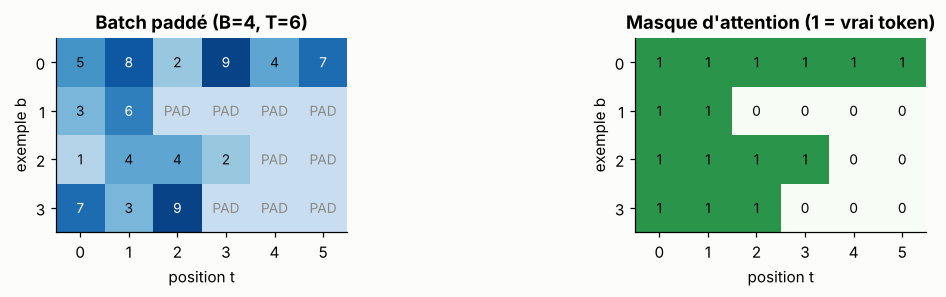

In [5]:
PAD = 0
sequences = [[5, 8, 2, 9, 4, 7], [3, 6], [1, 4, 4, 2], [7, 3, 9]]        # token ids of 4 sentences
T_max = max(len(s) for s in sequences)
batch = np.full((len(sequences), T_max), PAD)
for i, s in enumerate(sequences):
    batch[i, :len(s)] = s
mask = batch != PAD                                                          # True = real token

fig, axes = plt.subplots(1, 2, figsize=(11, 2.8))
axes[0].imshow(batch, cmap="Blues", vmin=-3, vmax=10)
for (i, j), v in np.ndenumerate(batch):
    axes[0].text(j, i, "PAD" if v == PAD else str(v), ha="center", va="center", fontsize=9,
                 color="#8a8984" if v == PAD else ("white" if v >= 6 else "#0b0b0b"))
axes[0].set_title("Batch paddé (B=4, T=6)")
axes[1].imshow(mask, cmap="Greens", vmin=0, vmax=1.4)
for (i, j), v in np.ndenumerate(mask):
    axes[1].text(j, i, "1" if v else "0", ha="center", va="center", fontsize=9)
axes[1].set_title("Masque d'attention (1 = vrai token)")
for ax in axes:
    ax.set_xlabel("position t"); ax.set_ylabel("exemple b"); ax.grid(False)
    ax.set_xticks(range(T_max)); ax.set_yticks(range(len(sequences)))
plt.tight_layout(); plt.show()

**Le masque sert partout** : pour ignorer les PAD dans une moyenne (*pooling*), dans l'attention (module 6), et dans la perte (on ne calcule pas d'erreur sur les PAD). Exemple de moyenne masquée, l'opération de base d'un classifieur de phrases :

$$
\bar h = \frac{\sum_{t} m_t\, h_t}{\sum_t m_t}
$$

In [6]:
H = rng.normal(size=(4, T_max, 3))                  # (B, T, C) hidden vectors (random here)
H[~mask] = 100.0                                    # garbage at PAD positions, as in real life
naive_mean = H.mean(axis=1)
masked_mean = (H * mask[..., None]).sum(1) / mask.sum(1, keepdims=True)
print("naive mean (polluted by PAD):\n", naive_mean.round(2))
print("masked mean:\n", masked_mean.round(2))

naive mean (polluted by PAD):
 [[ 0.28  0.08  0.07]
 [66.83 66.77 66.33]
 [33.82 33.82 32.96]
 [49.66 49.3  49.91]]
masked mean:
 [[ 0.28  0.08  0.07]
 [ 0.48  0.31 -1.02]
 [ 0.73  0.72 -0.56]
 [-0.67 -1.4  -0.19]]


### 5.3 La version PyTorch

In [ ]:
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence


class ToySequenceDataset(Dataset):
    """Variable-length sequences of token ids with a label."""

    def __init__(self, seqs, labels):
        self.seqs, self.labels = seqs, labels

    def __len__(self):
        return len(self.seqs)

    def __getitem__(self, i):
        return torch.tensor(self.seqs[i], dtype=torch.long), torch.tensor(self.labels[i], dtype=torch.long)


def collate_pad(batch, pad_id=0):
    seqs, labels = zip(*batch)
    lengths = torch.tensor([len(s) for s in seqs])
    padded = pad_sequence(seqs, batch_first=True, padding_value=pad_id)   # (B, T_max)
    mask = padded != pad_id                                                # (B, T_max) bool
    return {"input_ids": padded, "attention_mask": mask, "lengths": lengths, "labels": torch.stack(labels)}


ds = ToySequenceDataset(sequences, [1, 0, 1, 0])
loader = DataLoader(ds, batch_size=2, shuffle=True, collate_fn=collate_pad)
for b in loader:
    print({k: v.shape for k, v in b.items()})
    print(b["input_ids"], b["attention_mask"], sep="\n")
    break

> 💡 **Astuce d'efficacité** : padder à la longueur max *du batch* (et non du jeu de données) économise beaucoup de calcul. Encore mieux : regrouper les phrases de longueurs proches dans les mêmes batches (*bucketing*), ce que fait `group_by_length=True` dans Hugging Face.

## 6. Une boucle d'entraînement robuste

### 6.1 Le gradient clipping

Les réseaux récurrents et les Transformers subissent parfois des **pics de gradient** qui détruisent l'entraînement en un pas. Le *clipping par norme* plafonne la norme globale du gradient à $c$ sans changer sa direction :

$$
g \leftarrow g\cdot\min\left(1,\ \frac{c}{\lVert g\rVert_2}\right)
$$

où $\lVert g\rVert_2$ est calculé sur **tous** les paramètres concaténés. Valeur typique : $c = 1$.

In [7]:
g = rng.normal(size=1000) * np.r_[np.ones(999), 300.0]     # one exploding coordinate
for c in [None, 1.0]:
    gc = g if c is None else g * min(1.0, c / np.linalg.norm(g))
    print(f"clip={c}: norm={np.linalg.norm(gc):8.2f} | cosine with original direction = {gc @ g / np.linalg.norm(gc) / np.linalg.norm(g):.3f}")

clip=None: norm=   83.05 | cosine with original direction = 1.000
clip=1.0: norm=    1.00 | cosine with original direction = 1.000


### 6.2 La précision mixte

Sur GPU, calculer en 16 bits double à peu près la vitesse et divise la mémoire par deux. Deux formats :

In [8]:
f16 = np.finfo(np.float16)
print(f"float16 : max = {f16.max:.0f}, smallest normal = {f16.tiny:.1e}, eps = {f16.eps:.1e}")
# bfloat16 = float32 exponent (8 bits) + 7-bit mantissa (numpy has no native bfloat16):
print(f"bfloat16: max ≈ {(2 - 2**-7) * 2.0**127:.2e}, smallest normal ≈ {2.0**-126:.1e}, eps = {2**-7:.1e}")
with np.errstate(over="ignore"):
    print("float16 overflow example:", np.float16(70000.0), "| tiny gradient underflow:", np.float16(1e-8))

float16 : max = 65504, smallest normal = 6.1e-05, eps = 9.8e-04
bfloat16: max ≈ 3.39e+38, smallest normal ≈ 1.2e-38, eps = 7.8e-03
float16 overflow example: inf | tiny gradient underflow: 0.0


- **float16** : petite plage → les petits gradients deviennent 0 (*underflow*). Il faut un `GradScaler` qui multiplie la perte par un grand facteur avant `backward`, puis divise les gradients.
- **bfloat16** : même plage que float32 mais moins précis → pas besoin de scaler. **C'est le standard actuel** pour entraîner les modèles de langue (GPU Ampere et suivants).

### 6.3 Le squelette complet

In [ ]:
def set_seed(seed=0):
    import random
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def train_one_epoch(model, loader, optimizer, scheduler=None, device="cpu", clip=1.0, use_amp=False):
    model.train()                                            # enable dropout
    total_loss, n = 0.0, 0
    amp_dtype = torch.bfloat16 if use_amp else None
    for batch in loader:
        batch = {k: v.to(device, non_blocking=True) for k, v in batch.items()}
        with torch.autocast(device_type=device.split(":")[0], dtype=amp_dtype, enabled=use_amp):
            logits = model(batch["input_ids"], batch["attention_mask"])
            loss = F.cross_entropy(logits, batch["labels"])
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), clip)   # returns the norm BEFORE clipping
        optimizer.step()
        if scheduler is not None:
            scheduler.step()                                 # per-step schedule (warmup + cosine)
        total_loss += loss.item() * len(batch["labels"]); n += len(batch["labels"])
    return total_loss / n


@torch.no_grad()
def evaluate(model, loader, device="cpu"):
    model.eval()                                             # disable dropout
    total_loss, correct, n = 0.0, 0, 0
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        logits = model(batch["input_ids"], batch["attention_mask"])
        total_loss += F.cross_entropy(logits, batch["labels"], reduction="sum").item()
        correct += (logits.argmax(-1) == batch["labels"]).sum().item()
        n += len(batch["labels"])
    return total_loss / n, correct / n


def fit(model, train_loader, val_loader, epochs=10, lr=3e-4, weight_decay=0.01, warmup_frac=0.1,
        device="cpu", patience=3, ckpt_path="best.pt"):
    model.to(device)
    # no weight decay on biases and normalization parameters (standard practice for Transformers)
    decay = [p for n_, p in model.named_parameters() if p.ndim >= 2]
    no_decay = [p for n_, p in model.named_parameters() if p.ndim < 2]
    optimizer = torch.optim.AdamW([{"params": decay, "weight_decay": weight_decay},
                                   {"params": no_decay, "weight_decay": 0.0}], lr=lr)
    total_steps = epochs * len(train_loader)
    warmup = int(warmup_frac * total_steps)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda s: min(1.0, (s + 1) / max(1, warmup)) * 0.5 * (1 + np.cos(np.pi * min(1.0, s / total_steps))))
    best, bad_epochs, history = float("inf"), 0, []
    for ep in range(epochs):
        tr_loss = train_one_epoch(model, train_loader, optimizer, scheduler, device)
        va_loss, va_acc = evaluate(model, val_loader, device)
        history.append((tr_loss, va_loss, va_acc))
        print(f"epoch {ep:2d} | train loss {tr_loss:.4f} | val loss {va_loss:.4f} | val acc {va_acc:.3f}")
        if va_loss < best:                                   # early stopping on validation loss
            best, bad_epochs = va_loss, 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print("early stopping"); break
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    return history

## 7. Déboguer un réseau de neurones

Un réseau buggé **ne plante pas** : il apprend juste moins bien. D'où l'importance d'une routine de vérification systématique (inspirée de « A Recipe for Training Neural Networks », A. Karpathy) :

| Étape | Ce qu'on vérifie | Ce qu'on attend |
|---|---|---|
| 1. Perte initiale | perte au pas 0 | $\approx\log K$ pour $K$ classes |
| 2. Sur-apprendre un batch | entraîner sur 1 batch de ~16 exemples | perte → ~0, précision 100 % |
| 3. Formes | `assert` sur les formes aux points clés | pas de broadcasting accidentel |
| 4. Fuite entre exemples | modifier l'exemple $i$ et regarder le gradient sur l'exemple $j\ne i$ | gradient nul (sinon on mélange le batch par erreur) |
| 5. Normes des gradients | `clip_grad_norm_` renvoie la norme | ni 0, ni NaN, ni des pics de ×1000 |
| 6. Learning rate | balayage log | la perte baisse vite sans diverger |

In [ ]:
def overfit_one_batch(model, batch, steps=200, lr=1e-2):
    """A correct model + training loop must be able to memorize a single small batch."""
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for s in range(steps):
        logits = model(batch["input_ids"], batch["attention_mask"])
        loss = F.cross_entropy(logits, batch["labels"])
        opt.zero_grad(); loss.backward(); opt.step()
        if s % 50 == 0 or s == steps - 1:
            print(f"step {s:3d} loss {loss.item():.4f}")
    return loss.item()


def check_batch_independence(model, batch, i=0, j=1):
    """The loss of example i must not depend on the input of example j (catches wrong reshapes / norms over batch)."""
    model.eval()
    emb = model.embedding(batch["input_ids"]).detach().requires_grad_(True)
    logits = model.forward_from_embeddings(emb, batch["attention_mask"])
    logits[i].sum().backward()
    leak = emb.grad[j].abs().sum().item()
    print(f"gradient leaking from example {j} into example {i}: {leak:.2e}", "✅" if leak == 0 else "❌")

**Les erreurs classiques et leur message :**

| Message | Cause probable |
|---|---|
| `Expected all tensors to be on the same device` | un tenseur créé dans `forward` sans `device=x.device`, ou batch non déplacé |
| `expected scalar type Long but found Float` | étiquettes en float pour `cross_entropy` (il faut des `long`) |
| `mat1 and mat2 shapes cannot be multiplied (32x100 and 128x64)` | `d_in` de la couche ≠ dimension réelle de l'entrée |
| `view size is not compatible with input tensor's size and stride` | `view` après `transpose` → utiliser `reshape` ou `.contiguous()` |
| `one of the variables needed for gradient computation has been modified by an inplace operation` | opération en place (`x += ...`, `relu_`) sur un tenseur dont autograd a besoin |
| perte = `nan` | learning rate trop grand, `log(0)`, division par un masque vide, overflow en float16 |

## 8. Mini-projet : classifier des séquences de longueur variable

**Tâche synthétique** (on travaillera sur du vrai texte dès le module 2) : des séquences de tokens tirés d'un vocabulaire de 20 symboles, de longueur 5 à 30. L'étiquette vaut 1 si le token `7` apparaît **plus souvent** que le token `3`. Le modèle doit apprendre à reconnaître des tokens précis et à **compter** sur une longueur variable : c'est une version miniature d'un classifieur de sentiment « sac de mots ».

Architecture : `Embedding` → moyenne masquée → MLP → logits. (Les *embeddings* sont le sujet du module 3 : retiens pour l'instant que `nn.Embedding(V, d)` est une table de $V$ vecteurs appris, indexée par l'identifiant du token.)

example: [14, 17, 4, 2, 17, 1, 11, 2, 6, 10, 9, 8, 1, 1, 3, 1, 13, 10, 13, 5, 12, 15, 8, 9] -> 0
label balance: 0.507 | mean length: 18.6


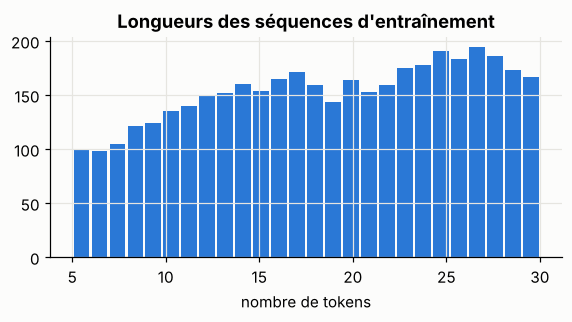

In [9]:
def make_counting_data(n, vocab=20, min_len=5, max_len=30, seed=0):
    r = np.random.default_rng(seed)
    seqs, labels = [], []
    while len(seqs) < n:
        L = r.integers(min_len, max_len + 1)
        s = r.integers(1, vocab, L)                      # 0 is reserved for PAD
        c7, c3 = (s == 7).sum(), (s == 3).sum()
        if c7 == c3:
            continue                                     # skip ties to keep labels unambiguous
        seqs.append(s.tolist()); labels.append(int(c7 > c3))
    return seqs, labels

tr_seqs, tr_labels = make_counting_data(4000, seed=0)
va_seqs, va_labels = make_counting_data(1000, seed=1)
print("example:", tr_seqs[0], "->", tr_labels[0])
print("label balance:", np.mean(tr_labels).round(3), "| mean length:", np.mean([len(s) for s in tr_seqs]).round(1))
plt.figure(figsize=(6, 2.6))
plt.hist([len(s) for s in tr_seqs], bins=26, color=PALETTE[0], rwidth=0.85)
plt.title("Longueurs des séquences d'entraînement"); plt.xlabel("nombre de tokens"); plt.show()

In [ ]:
class BagOfEmbeddingsClassifier(nn.Module):
    def __init__(self, vocab_size, d_emb=32, d_hidden=64, n_classes=2, pad_id=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_emb, padding_idx=pad_id)   # PAD vector fixed at 0
        self.mlp = nn.Sequential(nn.Linear(d_emb, d_hidden), nn.GELU(), nn.Dropout(0.1), nn.Linear(d_hidden, n_classes))

    def forward_from_embeddings(self, emb, attention_mask):
        m = attention_mask.unsqueeze(-1).to(emb.dtype)                      # (B, T, 1)
        pooled = (emb * m).sum(1) / m.sum(1).clamp(min=1.0)                 # masked mean, (B, d_emb)
        return self.mlp(pooled)                                             # (B, n_classes)

    def forward(self, input_ids, attention_mask):
        return self.forward_from_embeddings(self.embedding(input_ids), attention_mask)


set_seed(0)
train_loader = DataLoader(ToySequenceDataset(tr_seqs, tr_labels), batch_size=64, shuffle=True, collate_fn=collate_pad)
val_loader = DataLoader(ToySequenceDataset(va_seqs, va_labels), batch_size=256, collate_fn=collate_pad)

model = BagOfEmbeddingsClassifier(vocab_size=20)
first = next(iter(train_loader))
with torch.no_grad():
    init_loss = F.cross_entropy(model(first["input_ids"], first["attention_mask"]), first["labels"]).item()
print(f"[check 1] initial loss {init_loss:.3f} vs log(2) = {np.log(2):.3f}")
check_batch_independence(model, first)                                   # [check 4]

In [ ]:
print("[check 2] overfit one batch")
small = {k: v[:16] for k, v in first.items()}
overfit_one_batch(BagOfEmbeddingsClassifier(vocab_size=20), small)

In [ ]:
history = fit(model, train_loader, val_loader, epochs=30, lr=3e-3, device=device, patience=5)
h = np.array(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(h[:, 0], label="train"); axes[0].plot(h[:, 1], label="validation"); axes[0].set_title("Perte"); axes[0].legend()
axes[1].plot(h[:, 2], color=PALETTE[2]); axes[1].set_title("Précision de validation")
for ax in axes: ax.set_xlabel("époque")
plt.tight_layout(); plt.show()

**Analyse critique du résultat** (à faire après exécution) : la moyenne masquée calcule des **fréquences** de tokens, ce qui suffit en théorie pour comparer `#7` et `#3` (la longueur se simplifie dans le rapport). Tu devrais atteindre une précision élevée mais pas parfaite, les erreurs se concentrant sur les cas où `#7 − #3 = ±1` dans de longues séquences : la différence de fréquence devient minuscule. Vérifie-le :

In [ ]:
@torch.no_grad()
def accuracy_by_margin(model, seqs, labels):
    model.eval()
    b = collate_pad([(torch.tensor(s), torch.tensor(l)) for s, l in zip(seqs, labels)])
    pred = model(b["input_ids"].to(device), b["attention_mask"].to(device)).argmax(-1).cpu().numpy()
    margin = np.array([abs(np.sum(np.array(s) == 7) - np.sum(np.array(s) == 3)) for s in seqs])
    for m in range(1, 5):
        sel = margin == m
        print(f"|#7 - #3| = {m}: accuracy {np.mean(pred[sel] == np.array(labels)[sel]):.3f}  (n={sel.sum()})")

accuracy_by_margin(model, va_seqs, va_labels)

> 🎯 **Leçon de modélisation** : l'architecture impose un **biais inductif**. La moyenne perd l'ordre des mots et l'information de longueur. Pour « compter », une **somme** masquée serait plus naturelle. Pour comprendre « pas bon » ≠ « bon », il faudra un modèle sensible à l'ordre : RNN (module 4), Transformer (module 6).

## 9. Récapitulatif

| Outil | À retenir |
|---|---|
| Formes NLP | `(B, T, C)` ; ids de tokens en `long`, masques en `bool` |
| `view` / `reshape` | `view` sans copie mais exige la contiguïté ; `reshape` copie si besoin |
| Broadcasting | aligner à droite ; attention à `(N,1)` vs `(N,)` |
| Autograd | gradients accumulés → `zero_grad` ; `no_grad` à l'évaluation ; `backward(v)` = $v^\top J$ |
| `nn.Module` | paramètres enregistrés automatiquement ; `train()` / `eval()` ; sauvegarder le `state_dict` |
| Données | `collate_fn` qui padde + masque ; padder au max du batch |
| Boucle | `zero_grad → forward → loss → backward → clip → step → scheduler` |
| Débogage | perte initiale $\log K$, sur-apprendre un batch, indépendance du batch |

### 🏋️ Exercices

1. **Somme vs moyenne.** Remplace la moyenne masquée par une somme masquée dans `BagOfEmbeddingsClassifier`. La précision sur les petites marges s'améliore-t-elle ? Pourquoi faut-il alors faire attention à l'échelle (normaliser par une constante comme 30) ?
2. **Bug volontaire.** Dans `forward_from_embeddings`, remplace `m.sum(1)` par `m.sum(0)`. Lance `check_batch_independence`. Que se passe-t-il, et pourquoi ce test le détecte-t-il alors que l'entraînement « marche » ?
3. **Jacobienne.** Avec `torch.autograd.functional.jacobian`, calcule la jacobienne de la softmax pour `z = [1., 2., 3.]` et vérifie la formule $\partial p_k/\partial z_i = p_k(\delta_{ki}-p_i)$ du module 0.
4. **Bucketing.** Écris un `Sampler` qui trie les indices par longueur, les découpe en batches, puis mélange l'ordre des batches. Mesure la fraction de tokens PAD avant/après.

<details><summary>Indications</summary>

1. La somme conserve le compte absolu, qui est exactement la statistique utile ; mais sa valeur croît avec la longueur, d'où une normalisation par une constante (pas par la longueur réelle).
2. `m.sum(0)` somme sur le **batch** : la normalisation de l'exemple $i$ dépend du masque des autres exemples. La perte baisse quand même, mais les prédictions changent selon la composition du batch, un bug très difficile à voir autrement.
3. `J = torch.autograd.functional.jacobian(lambda z: torch.softmax(z, 0), z)` puis comparer à `torch.diag(p) - torch.outer(p, p)`.
</details>

**➡️ Module suivant : du texte aux nombres** (normalisation, tokenisation mot / caractère / sous-mot, BPE de zéro, sacs de mots, TF-IDF et premier classifieur de texte).